# **04 - Main Evaluation Pipeline**

## **1. Pipeline Objective**

## **2. Dependency Management**

### **2.1 Package Installation**

In [1]:
!pip install -q transformers accelerate bitsandbytes pandas matplotlib seaborn

### **2.2 Module Imports**

In [2]:
import os
import json
import gc
import re
import itertools
import time
from typing import List, Dict, Any

import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

### **2.3 Environment Variables**

In [3]:
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')
MODEL_ID: str = "Qwen/Qwen3-4B-Instruct-2507"

os.environ['HF_HOME'] = MODELS_DIR

print(f"[MODEL] id='{MODEL_ID}' | status=CONFIGURING")

[MODEL] id='Qwen/Qwen3-4B-Instruct-2507' | status=CONFIGURING


## **3. Resource Allocation**

### **3.1 Identity & Access Management (IAM)**

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')

    secrets_path = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r') as f:
            secrets = json.load(f)
        hf_token = secrets.get("HF_TOKEN")
        if hf_token:
            from huggingface_hub import login
            login(token=hf_token)
            print("[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'")
except ImportError:
    print("[ENVIRONMENT] status=LOCAL | component='Google Drive'")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'


In [5]:
for d in [DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

## **4. Prompt Generator Node**

In [6]:
main_path = os.path.join(DATA_PROCESSED_DIR, 'indopref_main.parquet')
try:
    df_main = pd.read_parquet(main_path)
    print(f"[DATASET] split='main' | samples={len(df_main)} | status=LOADED")
except FileNotFoundError:
    print(f"[DATASET] split='main' | status=NOT_FOUND | path='{main_path}'")

[DATASET] split='main' | samples=369 | status=LOADED


## **5. LLM Initialization (Quantized)**

In [7]:
def format_prompt(p_id: str, input_text: str, resp_A: str, resp_B: str) -> str:
    if p_id == "P1":
        return (
            "Tugas Anda adalah mengevaluasi dua respons AI terhadap sebuah Input.\n"
            "Bandingkan Response A dan Response B secara keseluruhan.\n"
            "Pilih respons yang lebih baik secara objektif.\n\n"
            f"[Input]\n{input_text}\n\n"
            f"[Response A]\n{resp_A}\n\n"
            f"[Response B]\n{resp_B}\n\n"
            "Kandidat mana yang lebih baik? Jawab secara mutlak HANYA dengan huruf A atau B tanpa teks tambahan apa pun."
        )
    elif p_id == "P2":
        return (
            "Sebagai juri penilai, evaluasi Response A dan Response B berdasarkan tiga kriteria berikut:\n"
            "1. Akurasi (Correctness): Apakah respons memberikan informasi yang benar?\n"
            "2. Relevansi (Relevance): Apakah respons menjawab instruksi secara langsung?\n"
            "3. Kejelasan (Clarity): Apakah respons mudah dipahami dan tidak bertele-tele?\n\n"
            f"[Instruksi]\n{input_text}\n\n"
            f"[Response A]\n{resp_A}\n\n"
            f"[Response B]\n{resp_B}\n\n"
            "Berdasarkan kriteria di atas, respons mana yang lebih baik? Jawab secara mutlak HANYA dengan huruf A atau B tanpa penjelasan tambahan apa pun."
        )
    elif p_id == "P3":
        return (
            f"[Konteks Instruksi]\n{input_text}\n\n"
            f"[Kandidat A]\n{resp_A}\n\n"
            f"[Kandidat B]\n{resp_B}\n\n"
            "Pertanyaan Evaluasi: Berdasarkan instruksi di atas, kandidat manakah yang menyajikan jawaban yang lebih tepat dan berguna? Jawab HANYA dengan huruf A atau B."
        )
    return ""

def apply_chat_template(tokenizer, text: str) -> str:
    messages = [
        {"role": "system", "content": "You are an impartial and expert AI evaluator. You must evaluate the quality of two AI responses objectively based strictly on the provided instructions. Do not show preference for length unless length adds necessary value. Answer strictly as requested."},
        {"role": "user", "content": text}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)
allocated_vram = torch.cuda.memory_allocated() / 1024**3
print(f"[MODEL] status=LOADED | vram='{allocated_vram:.2f} GB'")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[MODEL] status=LOADED | vram='2.49 GB'


## **6. Symmetrical Execution Engine**

### **6.1 State Inspection (Idempotency Check)**

In [9]:
main_results_path = os.path.join(RESULTS_DIR, 'main_outputs.jsonl')

processed_combinations = set()
if os.path.exists(main_results_path):
    with open(main_results_path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data = json.loads(line)
                unique_key = (data['sample_id'], data['prompt_id'], data['position'])
                processed_combinations.add(unique_key)

print(f"[RESUME] processed={len(processed_combinations)} | status=ACTIVE")

[RESUME] processed=2214 | status=ACTIVE


### **6.2 Compute Loop**

In [10]:
prompts = ["P1", "P2", "P3"]
positions = ["AB", "BA"]
total_iterations = len(df_main) * len(prompts) * len(positions)

print(
    f"[INFERENCE] total_iterations={total_iterations} | "
    f"status=STARTED"
)

pbar = tqdm(total=total_iterations, desc="Factorial Inference")
pbar.update(len(processed_combinations))

with torch.inference_mode():
    for index, row in df_main.iterrows():
        sample_id = int(row['original_id'])
        input_text = row['input']
        human_winner = "A" if row['chosen_model'] == row['response_1'] else "B"

        for p_id in prompts:
            for pos in positions:
                if (sample_id, p_id, pos) in processed_combinations:
                    continue

                if pos == "AB":
                    resp_A, resp_B = row['response_1'], row['response_2']
                    current_human = human_winner
                else:
                    resp_A, resp_B = row['response_2'], row['response_1']
                    current_human = "B" if human_winner == "A" else "A"

                start_time = time.time()
                raw_prompt = format_prompt(p_id, input_text, resp_A, resp_B)
                formatted_prompt = apply_chat_template(tokenizer, raw_prompt)

                inputs = tokenizer(formatted_prompt, return_tensors="pt").to(model.device)

                outputs = model.generate(
                    **inputs,
                    max_new_tokens=10,
                    do_sample=False,
                    pad_token_id=tokenizer.eos_token_id
                )

                input_len = inputs['input_ids'].shape[1]
                generated_tokens = outputs[0][input_len:]
                raw_output = tokenizer.decode(generated_tokens, skip_special_tokens=True)

                runtime = time.time() - start_time
                output_len = len(generated_tokens)
                tps = output_len / runtime if runtime > 0 else 0.0

                record = {
                    "sample_id": sample_id,
                    "domain": row['domain'],
                    "prompt_id": p_id,
                    "position": pos,
                    "human_preference": current_human,
                    "raw_output": raw_output,
                    "runtime_sec": round(runtime, 2),
                    "output_tokens": output_len,
                    "tps": round(tps, 2)
                }

                with open(main_results_path, 'a', encoding='utf-8') as f:
                    f.write(json.dumps(record) + '\n')

                processed_combinations.add((sample_id, p_id, pos))
                pbar.update(1)

                del inputs, outputs
                torch.cuda.empty_cache()
                gc.collect()

pbar.close()

[INFERENCE] total_iterations=2214 | status=STARTED


Factorial Inference:   0%|          | 0/2214 [00:00<?, ?it/s]

## **7. Performance Telemetry**

### **7.1 Semantic Extraction**

In [11]:
results = []
with open(main_results_path, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            results.append(json.loads(line))

df_res = pd.DataFrame(results)

def parse_decision(raw_output: str):
    clean_text: str = raw_output.strip().upper()
    match = re.search(r'\b([AB])\b', clean_text)
    if match:
        return match.group(1)
    return "INVALID"

df_res['parsed_decision'] = df_res['raw_output'].apply(parse_decision)
df_res['is_match'] = df_res['parsed_decision'] == df_res['human_preference']

invalid_count = (df_res['parsed_decision'] == "INVALID").sum()
invalid_rate = (invalid_count / len(df_res)) * 100

print(
    f"[METRICS] total={len(df_res)} | "
    f"parse_failures={invalid_count} | "
    f"failure_rate={invalid_rate:.1f}%"
)
assert invalid_rate < 10.0, (
    "[INFERENCE] status=FAILED | "
    "error='parse_failure_rate_exceeded' | "
    f"actual={invalid_rate:.1f}% | "
    "threshold=10.0%"
)

[METRICS] total=3047 | parse_failures=117 | failure_rate=3.8%


### **7.2 Position Bias Profiling**

In [12]:
df_valid = df_res[df_res['parsed_decision'] != "INVALID"].copy()
pos_dist = df_valid['parsed_decision'].value_counts(normalize=True) * 100

print(pos_dist)
if 'A' in pos_dist and pos_dist['A'] > 55:
    print("[ANALYSIS] metric='position_bias' | observation='A-dominant'")
else:
    print("[ANALYSIS] metric='position_bias' | observation='balanced'")

parsed_decision
B    51.740614
A    48.259386
Name: proportion, dtype: float64
[ANALYSIS] metric='position_bias' | observation='balanced'


### **7.3 Prompt Sensitivity Profiling**

In [13]:
prompt_accuracy = df_valid.groupby('prompt_id')['is_match'].mean() * 100
print(prompt_accuracy)

prompt_id
P1    58.267717
P2    49.015748
P3    47.438753
Name: is_match, dtype: float64


### **7.4 Telemetry Dashboard**

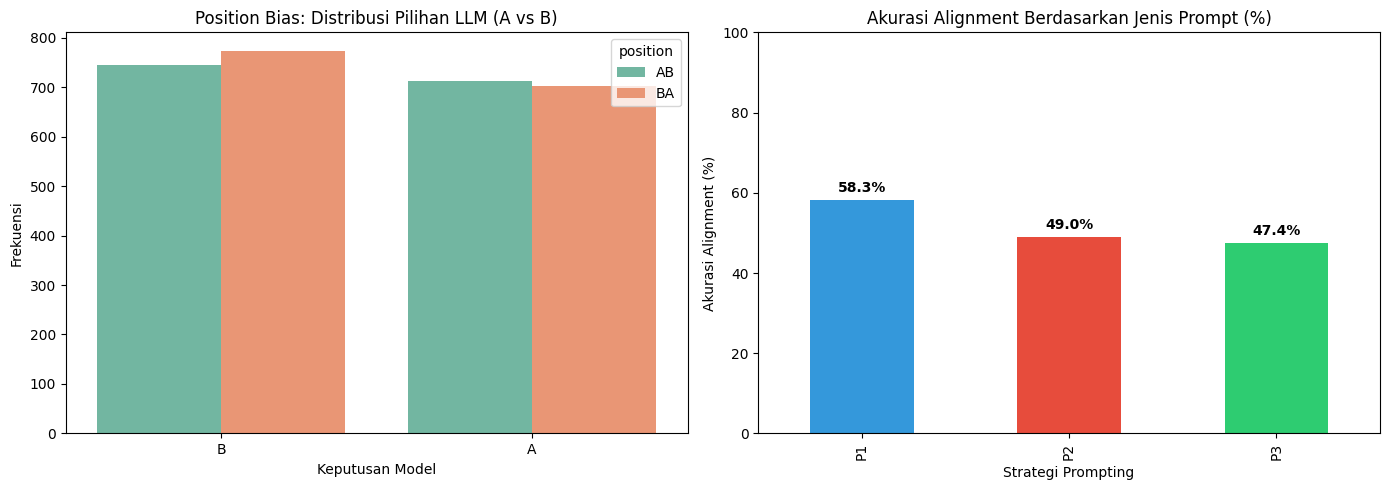

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_valid, x='parsed_decision', ax=axes[0], hue='position', palette='Set2')
axes[0].set_title('Position Bias: Distribusi Pilihan LLM (A vs B)')
axes[0].set_xlabel('Keputusan Model')
axes[0].set_ylabel('Frekuensi')

prompt_accuracy.plot(kind='bar', ax=axes[1], color=['#3498db', '#e74c3c', '#2ecc71'])
axes[1].set_title('Akurasi Alignment Berdasarkan Jenis Prompt (%)')
axes[1].set_xlabel('Strategi Prompting')
axes[1].set_ylabel('Akurasi Alignment (%)')
axes[1].set_ylim(0, 100)

for i, v in enumerate(prompt_accuracy):
    axes[1].text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()